# Space Weather & Heliophysics in `Geocroissant`: NASA SDO SuryaBench 🥐

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="float: right; margin-left: 24px; margin-top: 6px; margin-bottom: 12px; border-radius: 8px;">

**Croissant 🥐** standardizes machine learning dataset descriptions into a single JSON-LD document. **GeoCroissant** extends Croissant with geospatial and space weather attributes, covering coordinate reference systems (CRS), spatial and temporal resolutions, spectral band configurations, and sensor characteristics.

This notebook demonstrates how to curate, catalog, and load space weather datasets using GeoCroissant. We use NASA's [SuryaBench](https://registry.opendata.aws/surya-bench/) dataset, an open benchmark dataset derived from NASA's Solar Dynamics Observatory (SDO) and curated by NASA IMPACT and IBM Research ([Roy et al., 2024](https://arxiv.org/abs/2410.10841)).

In [1]:
# pip install netCDF4 xarray hdf5plugin torch mlcroissant sunpy

import os
import subprocess
import glob
import json
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import netCDF4
import xarray as xr
import hdf5plugin
import torch
from torch.utils.data import IterableDataset, DataLoader
import mlcroissant as mlc
import sunpy.visualization.colormaps as sunpy_cm

## Inspecting SDO NetCDF Cubes

SuryaBench files are hosted on AWS Open Data in public S3 bucket `s3://nasa-surya-bench/`. Each observation is stored as a NetCDF-4 (`.nc`) files

In [ ]:
os.makedirs("data", exist_ok=True)
sample_files = [
    "data/20100513_0012.nc",
    "data/20100513_0024.nc",
    "data/20100513_0036.nc",
]

# Auto-download each of the 3 sample files if missing
for fpath in sample_files:
    fname = os.path.basename(fpath)
    if not os.path.exists(fpath) or os.path.getsize(fpath) < 500 * 1024 * 1024:
        print(f"Downloading {fname} from AWS S3 (559 MB)...")
        s3_url = f"s3://nasa-surya-bench/2010/05/{fname}"
        subprocess.run(
            ["aws", "s3", "cp", "--no-sign-request", s3_url, fpath], check=True
        )

# Inspect all 3 files with xarray
for fpath in sample_files:
    with xr.open_dataset(fpath) as ds:
        t_obs = ds.attrs.get("data_time", "N/A")
        ny, nx = ds.sizes["y"], ds.sizes["x"]
        print(
            f"File: {os.path.basename(fpath)} | Time: {t_obs} | Grid: ({ny}, {nx}) |"
            f" Variables: {len(ds.data_vars)}"
        )

# Detailed channel summary from the first file
with xr.open_dataset(sample_files[0]) as ds:
    print(f"\nChannels summary ({len(ds.data_vars)} variables):")
    for name, var in ds.data_vars.items():
        desc = var.attrs.get("description", "")
        unit = var.attrs.get("unit", "")
        print(
            f"{name:8s} | shape={var.shape} | dtype={var.dtype} | unit={unit:6s} |"
            f" {desc}"
        )

File: 20100513_0012.nc | Time: 20100513_0012 | Grid: (4096, 4096) | Variables: 13
File: 20100513_0024.nc | Time: 20100513_0024 | Grid: (4096, 4096) | Variables: 13
File: 20100513_0036.nc | Time: 20100513_0036 | Grid: (4096, 4096) | Variables: 13

Channels summary (13 variables):
  aia94    | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 94 Angstrom
  aia131   | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 131 Angstrom
  aia171   | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 171 Angstrom
  aia193   | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 193 Angstrom
  aia211   | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 211 Angstrom
  aia304   | shape=(4096, 4096) | dtype=float32 | unit=DN/s   | Level-1.5 AIA image for wavelength 304 Angstrom
  aia335   | shape=(4096, 4096) | dtype=float32 |

## Defining the GeoCroissant Metadata

In [3]:
# 1. Dynamic Catalog Generation (5 consecutive synoptic observations)
def generate_sdo_catalog(
    start_dt=datetime(2010, 5, 13, 0, 12), count=5, step_minutes=12
):
    base_url = "https://nasa-surya-bench.s3.amazonaws.com"
    base_s3 = "s3://nasa-surya-bench"
    catalog = []
    for i in range(count):
        cur_dt = start_dt + timedelta(minutes=i * step_minutes)
        obs_id = cur_dt.strftime("%Y%m%d_%H%M")
        year_str = cur_dt.strftime("%Y")
        month_str = cur_dt.strftime("%m")
        dt_iso = cur_dt.strftime("%Y-%m-%dT%H:%M:%SZ")
        rel_path = f"{year_str}/{month_str}/{obs_id}.nc"
        catalog.append({
            "observations_index/observation_id": obs_id,
            "observations_index/datetime": dt_iso,
            "observations_index/url": f"{base_url}/{rel_path}",
            "observations_index/s3_uri": f"{base_s3}/{rel_path}",
        })
    return catalog


catalog_data = generate_sdo_catalog(count=5)

# 2. Distribution FileObjects pointing to remote AWS S3 endpoints
known_hashes = {
    "20100513_0012": "077967f6ae9a23a42b3d397c141f46fff15a659a2d3570ce54856d4f21fb4f8b",
    "20100513_0024": "ba46de99a6f0e1a2fc432400f0cb151aab57b2ebae50902e0fa01ee2667bb1fa",
    "20100513_0036": "6f7dc092ac22a6dd8e4d558907bd63f77c7ab83b6bacd724ea8eb182ce063e1e",
}

distribution_files = []
for obs_id, sha in known_hashes.items():
    distribution_files.append(
        mlc.FileObject(
            id=f"sdo-level15-nc-{obs_id.replace('_', '-')}",
            name=f"{obs_id}.nc",
            description=f"SDO Level-1.5 4096x4096 NetCDF cube for observation {obs_id}",
            content_url=(
                f"https://nasa-surya-bench.s3.amazonaws.com/2010/05/{obs_id}.nc"
            ),
            encoding_formats=["application/x-netcdf"],
            sha256=sha,
        )
    )

# 3. Catalog Index RecordSet with geocr:timeSeriesIndex
catalog_fields = [
    mlc.Field(
        id="observations_index/observation_id",
        name="observation_id",
        description="Unique observation identifier",
        data_types=[mlc.DataType.TEXT],
    ),
    mlc.Field(
        id="observations_index/datetime",
        name="datetime",
        description="Observation timestamp (ISO 8601)",
        data_types=[mlc.DataType.DATE],
    ),
    mlc.Field(
        id="observations_index/url",
        name="url",
        description="Remote HTTPS download URL on AWS S3",
        data_types=[mlc.DataType.URL],
    ),
    mlc.Field(
        id="observations_index/s3_uri",
        name="s3_uri",
        description="AWS S3 URI for high-throughput direct access",
        data_types=[mlc.DataType.TEXT],
    ),
]

record_set_catalog = mlc.RecordSet(
    id="observations_index",
    name="observations_index",
    description=(
        "Chronological catalog index of SDO observations with remote S3 endpoints"
    ),
    fields=catalog_fields,
    data=catalog_data,
    time_series_index="observations_index/datetime",
)

# 4. Observation Data Fields & Spectral Bands
channels = [
    # (variable_name, description, center_wavelength, bandwidth_fwhm)
    ("aia94", "AIA 94 Angstrom EUV channel (Fe XVIII, ~6.3 MK)", 94.0, 1.8),
    (
        "aia131",
        "AIA 131 Angstrom EUV channel (Fe VIII, XXI, ~0.4 MK & 10 MK)",
        131.0,
        2.5,
    ),
    ("aia171", "AIA 171 Angstrom EUV channel (Fe IX, ~0.6 MK)", 171.0, 4.4),
    (
        "aia193",
        "AIA 193 Angstrom EUV channel (Fe XII, XXIV, ~1.2 MK & 20 MK)",
        193.0,
        5.6,
    ),
    ("aia211", "AIA 211 Angstrom EUV channel (Fe XIV, ~2.0 MK)", 211.0, 6.3),
    ("aia304", "AIA 304 Angstrom EUV channel (He II, ~0.05 MK)", 304.0, 14.0),
    ("aia335", "AIA 335 Angstrom EUV channel (Fe XVI, ~2.5 MK)", 335.0, 18.0),
    (
        "aia1600",
        "AIA 1600 Angstrom UV continuum channel (C IV, ~10000 K)",
        1600.0,
        28.0,
    ),
    (
        "hmi_m",
        "HMI Line-of-Sight Magnetogram (Fe I 6173.3 Angstrom, Gauss)",
        6173.3,
        0.076,
    ),
    ("hmi_bx", "HMI Vector Magnetic Field X-component (Gauss)", 6173.3, 0.076),
    ("hmi_by", "HMI Vector Magnetic Field Y-component (Gauss)", 6173.3, 0.076),
    ("hmi_bz", "HMI Vector Magnetic Field Z-component (Gauss)", 6173.3, 0.076),
    ("hmi_v", "HMI Line-of-Sight Doppler Velocity (m/s)", 6173.3, 0.076),
]

fields_obs = []
spectral_bands = []
for name, desc, wave, bw in channels:
    fields_obs.append(
        mlc.Field(
            id=f"sdo_observations/{name}",
            name=name,
            description=desc,
            data_types=[mlc.DataType.IMAGE_OBJECT],
            is_array=True,
            array_shape="4096,4096",
            source=mlc.Source(
                file_object="sdo-level15-nc-20100513-0012",
                extract=mlc.Extract(column=name),
            ),
        )
    )
    spectral_bands.append(
        mlc.SpectralBand(
            name=name,
            center_wavelength=mlc.QuantitativeValue(value=wave, unitText="angstrom"),
            bandwidth=mlc.QuantitativeValue(value=bw, unitText="angstrom"),
        )
    )

record_set_obs = mlc.RecordSet(
    id="sdo_observations",
    name="sdo_observations",
    description=(
        "Level-1.5 full-disk solar observations across 8 AIA EUV and 5 HMI channels"
    ),
    fields=fields_obs,
)

# 5. GeoCroissant Metadata with Space Weather Descriptors
metadata = mlc.Metadata(
    name="nasa-sdo-surya-bench",
    description=(
        "Machine learning (ML)-ready solar dataset curated from NASA Solar Dynamics"
        " Observatory (SDO) observations (May 13, 2010 – December 31, 2024). Contains"
        " Level-1.5 full-disk 4096x4096 multi-wavelength imagery from the Atmospheric"
        " Imaging Assembly (AIA) across 8 EUV channels and magnetic field / Doppler"
        " velocity measurements from the Helioseismic and Magnetic Imager (HMI) across"
        " 5 channels at 12-minute cadence."
    ),
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/RAI/",
        "http://mlcommons.org/croissant/geo/",
    ],
    url="https://registry.opendata.aws/surya-bench/",
    cite_as=(
        "@article{roy2024surya,\n  title={AI Foundation Model for Heliophysics:"
        " Applications, Design, and Implementation},\n  author={Roy, Sujit and Singh,"
        " Tufan and Freitag, Marcus and Schmude, Johannes and Lal, Rohit and Hegde,"
        " Dinesha and Ranjan, Soumya and Lin, Alan and Gaur, Vishal and Vos, Etienne"
        " and Ghosal, Rahul},\n  journal={arXiv preprint arXiv:2410.10841},\n "
        " year={2024}\n}"
    ),
    date_published="2024-10-14",
    version="1.0.0",
    license="https://creativecommons.org/licenses/by/4.0/",
    keywords=[
        "SDO",
        "heliophysics",
        "solar dynamics observatory",
        "AIA",
        "HMI",
        "space weather",
        "solar flares",
        "extreme ultraviolet",
        "magnetogram",
        "SuryaBench",
    ],
    creators=[
        mlc.Person(name="Sujit Roy", email="sujit.roy@nasa.gov"),
        mlc.Person(name="Hong Lin", email="hong.lin@uah.edu"),
        mlc.Person(name="Dinesha V Hegde"),
        mlc.Person(name="Johannes Schmude"),
        mlc.Person(name="Rohit Lal"),
        mlc.Person(name="Vishal Gaur"),
        mlc.Organization(name="NASA IMPACT"),
        mlc.Organization(name="University of Alabama in Huntsville"),
    ],
    coordinate_reference_system="Helioprojective-Cartesian",
    spatial_resolution=mlc.QuantitativeValue(value=0.6, unitText="arcsec"),
    temporal_resolution=mlc.QuantitativeValue(value=12, unitText="min"),
    multi_wavelength_configuration=mlc.MultiWavelengthConfiguration(
        channel_list=[
            "94Å",
            "131Å",
            "171Å",
            "193Å",
            "211Å",
            "304Å",
            "335Å",
            "1600Å",
            "6173Å",
        ]
    ),
    solar_instrument_characteristics=mlc.SolarInstrumentCharacteristics(
        observatory="SDO",
        instrument="AIA,HMI",
    ),
    band_configuration=mlc.BandConfiguration(
        total_bands=13,
        band_names_list=[ch[0] for ch in channels],
    ),
    spectral_band_metadata=spectral_bands,
    distribution=distribution_files,
    record_sets=[record_set_catalog, record_set_obs],
)

print(
    f"GeoCroissant metadata instantiated successfully with {len(catalog_data)} catalog"
    f" entries and {len(distribution_files)} distribution files."
)

GeoCroissant metadata instantiated successfully with 5 catalog entries and 3 distribution files.


## Serializing to JSON-LD

In [4]:
output_json = "sdo_surya_bench.json"
meta_json = metadata.to_json()

with open(output_json, "w") as f:
    json.dump(meta_json, f, indent=2)

print(f"Saved GeoCroissant JSON-LD to {output_json}")

Saved GeoCroissant JSON-LD to sdo_surya_bench.json


## Validating the Metadata

Validate `sdo_surya_bench.json` using the MLCroissant command-line validation tool:

In [5]:
!mlcroissant validate --jsonld=sdo_surya_bench.json

I1110 02:35:06.486787 132281827632960 validate.py:53] Done.


## Loading Dataset & Iterating Observations from Catalog

In [6]:
# Load GeoCroissant dataset once
dataset = mlc.Dataset("sdo_surya_bench.json")
catalog = list(dataset.records("observations_index"))

print(f"Dataset: {dataset.metadata.name}")
print(f"Total catalog records: {len(catalog)}. Streaming first 3 observations:\n")

loaded_batches = []
for record in catalog[:3]:
    obs_id = record["observations_index/observation_id"]
    dt = record["observations_index/datetime"]
    url = record["observations_index/url"]

    local_path = f"data/{obs_id}.nc"
    file_path = local_path if os.path.exists(local_path) else url

    with xr.open_dataset(file_path) as ds:
        loaded_batches.append({
            "observation_id": obs_id,
            "datetime": dt,
            "aia94": ds["aia94"].values[::2, ::2],
            "aia171": ds["aia171"].values[::2, ::2],
            "aia193": ds["aia193"].values[::2, ::2],
            "aia304": ds["aia304"].values[::2, ::2],
            "hmi_m": ds["hmi_m"].values[::2, ::2],
        })
    print(f"  [{obs_id}] {dt} | Loaded from {file_path}")

print(f"Successfully loaded {len(loaded_batches)} observation batches.")

Dataset: nasa-sdo-surya-bench
Total catalog records: 5. Streaming first 3 observations:

  [20100513_0012] 2010-05-13T00:12:00Z | Loaded from data/20100513_0012.nc
  [20100513_0024] 2010-05-13T00:24:00Z | Loaded from data/20100513_0024.nc
  [20100513_0036] 2010-05-13T00:36:00Z | Loaded from data/20100513_0036.nc
Successfully loaded 3 observation batches.


## Multi-Instrument Solar Visualization

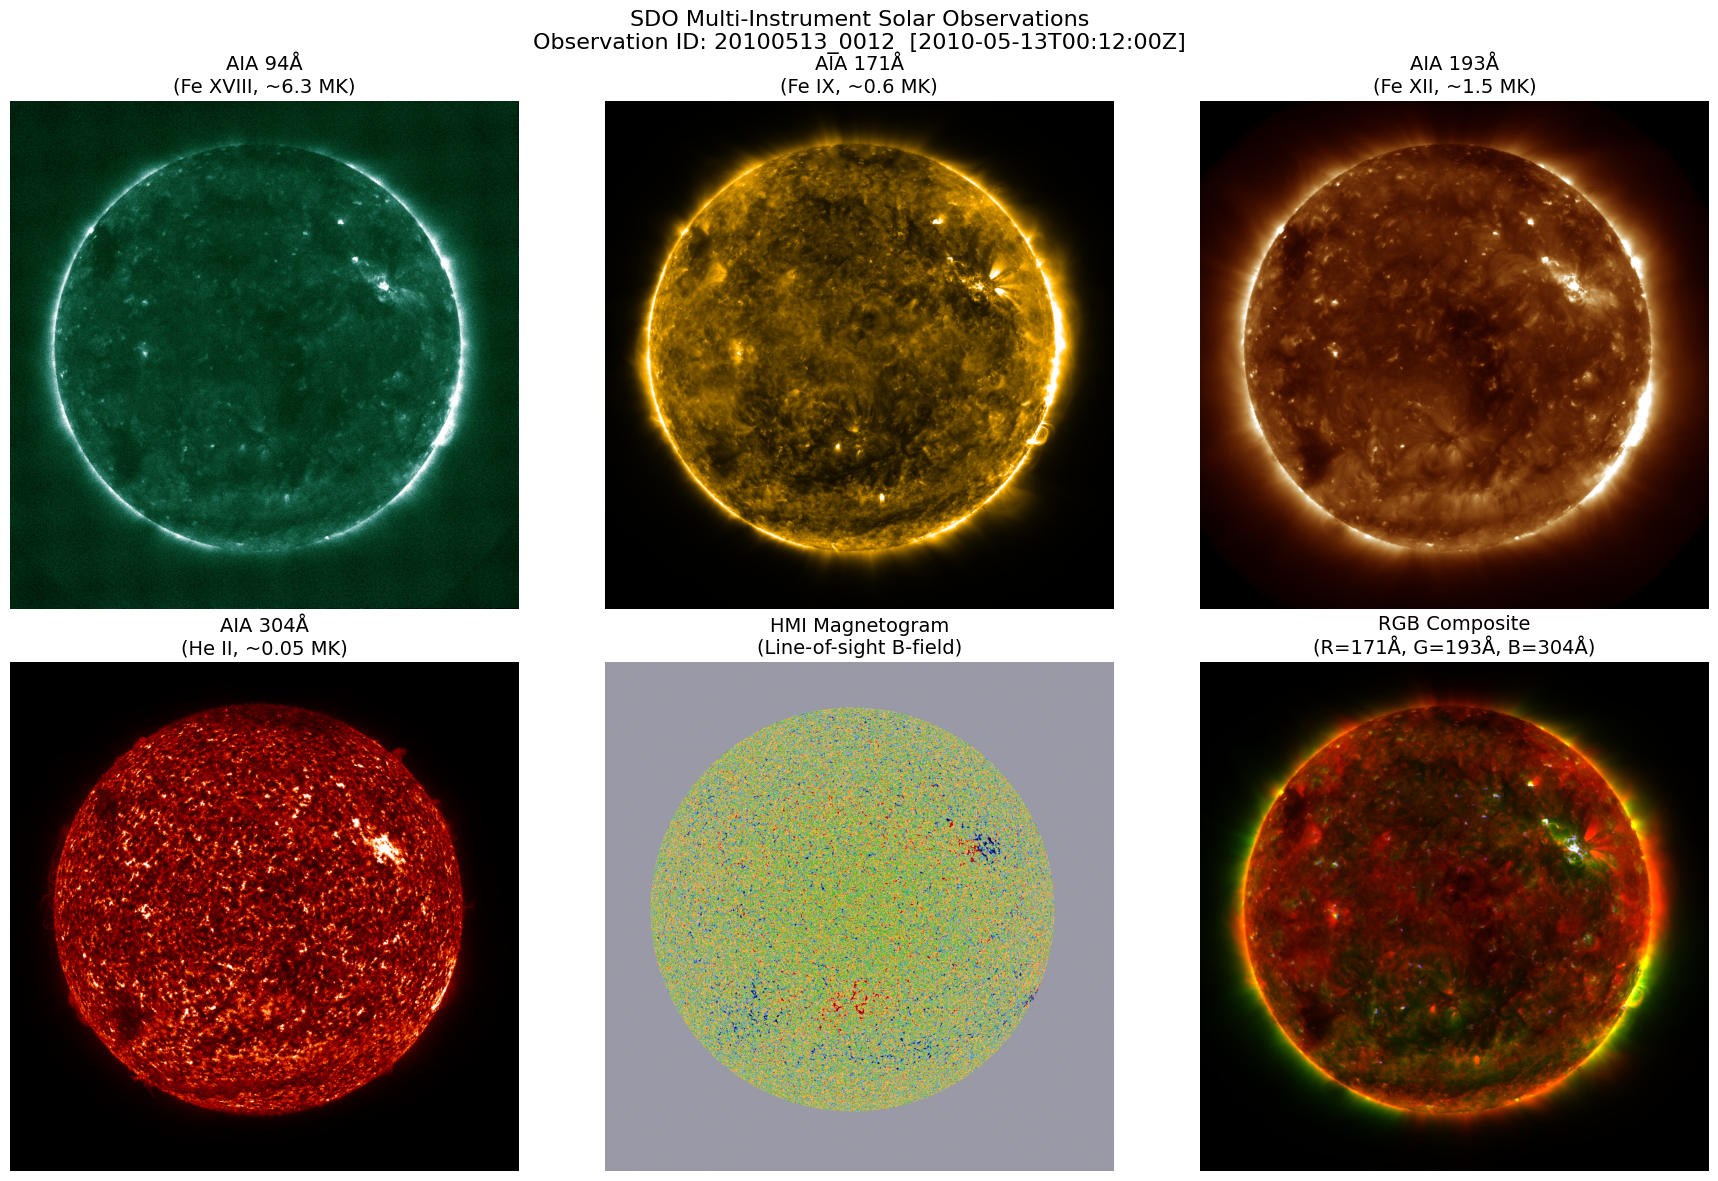

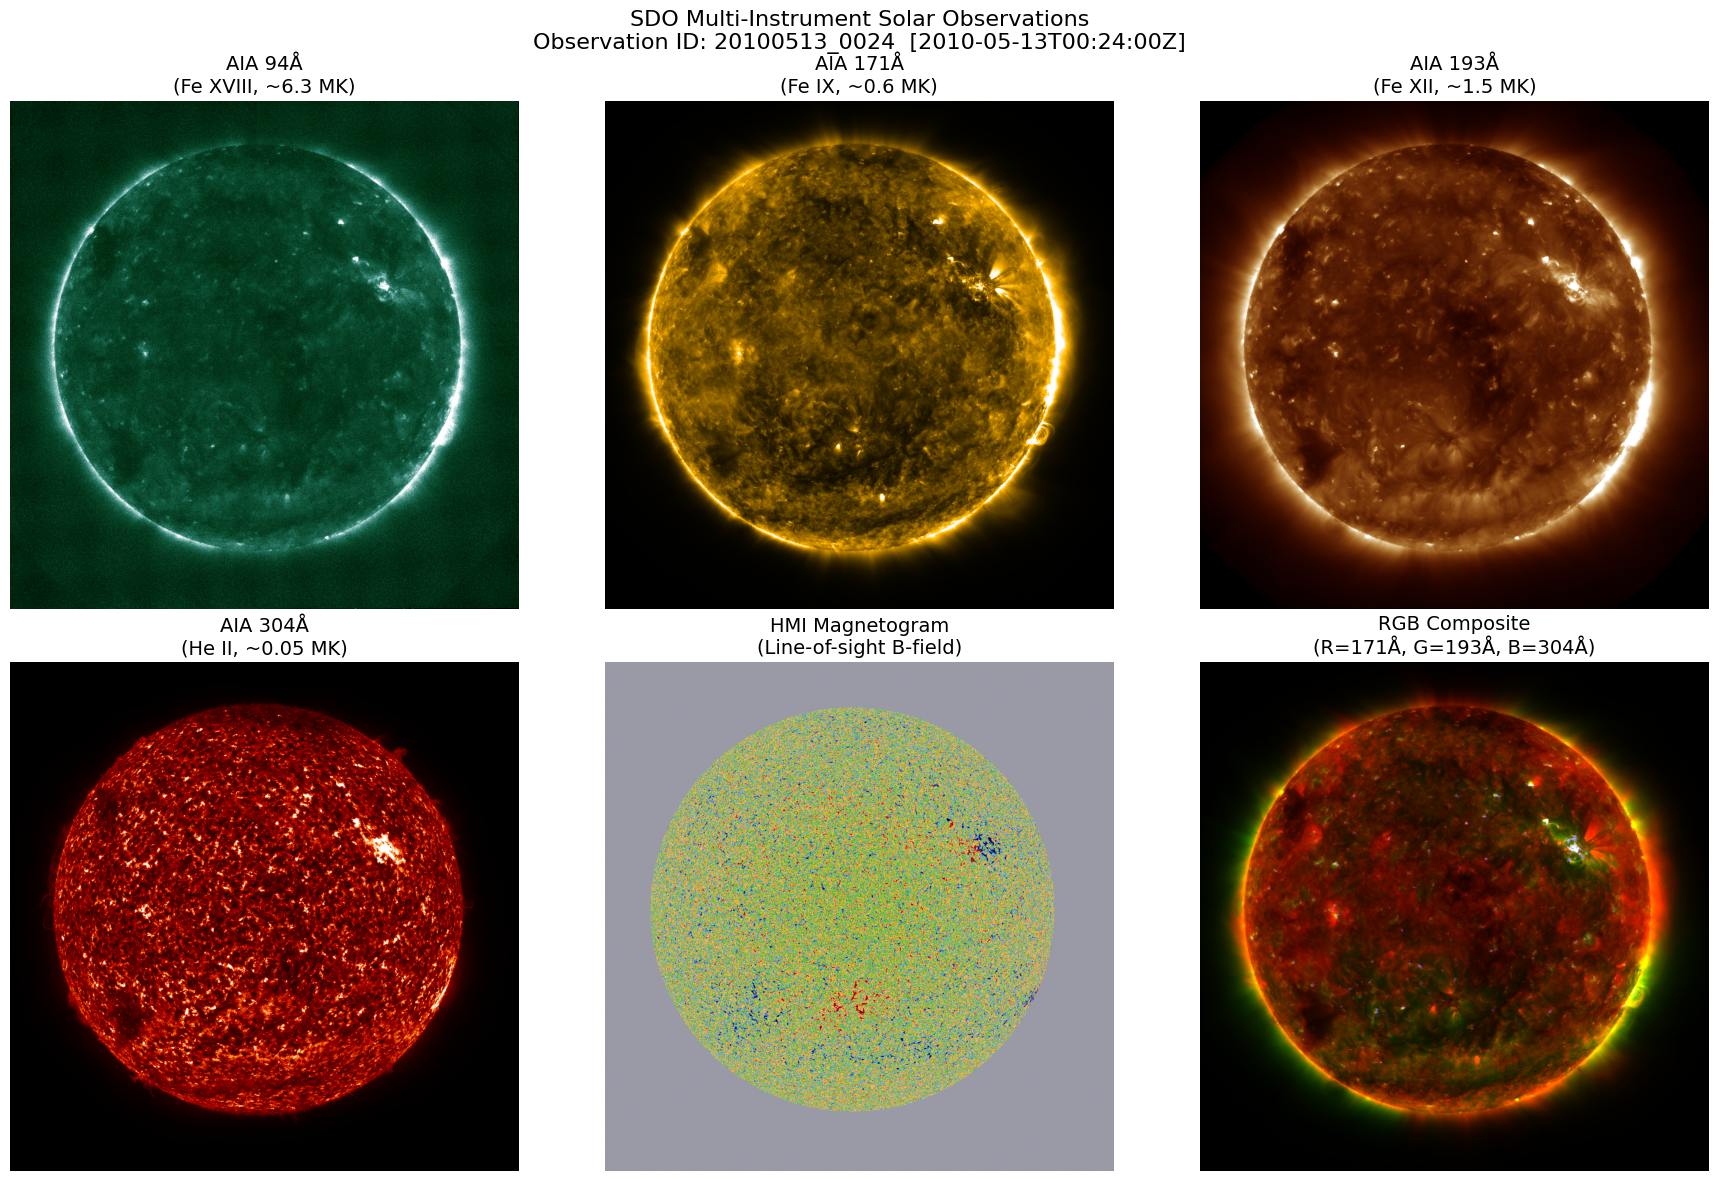

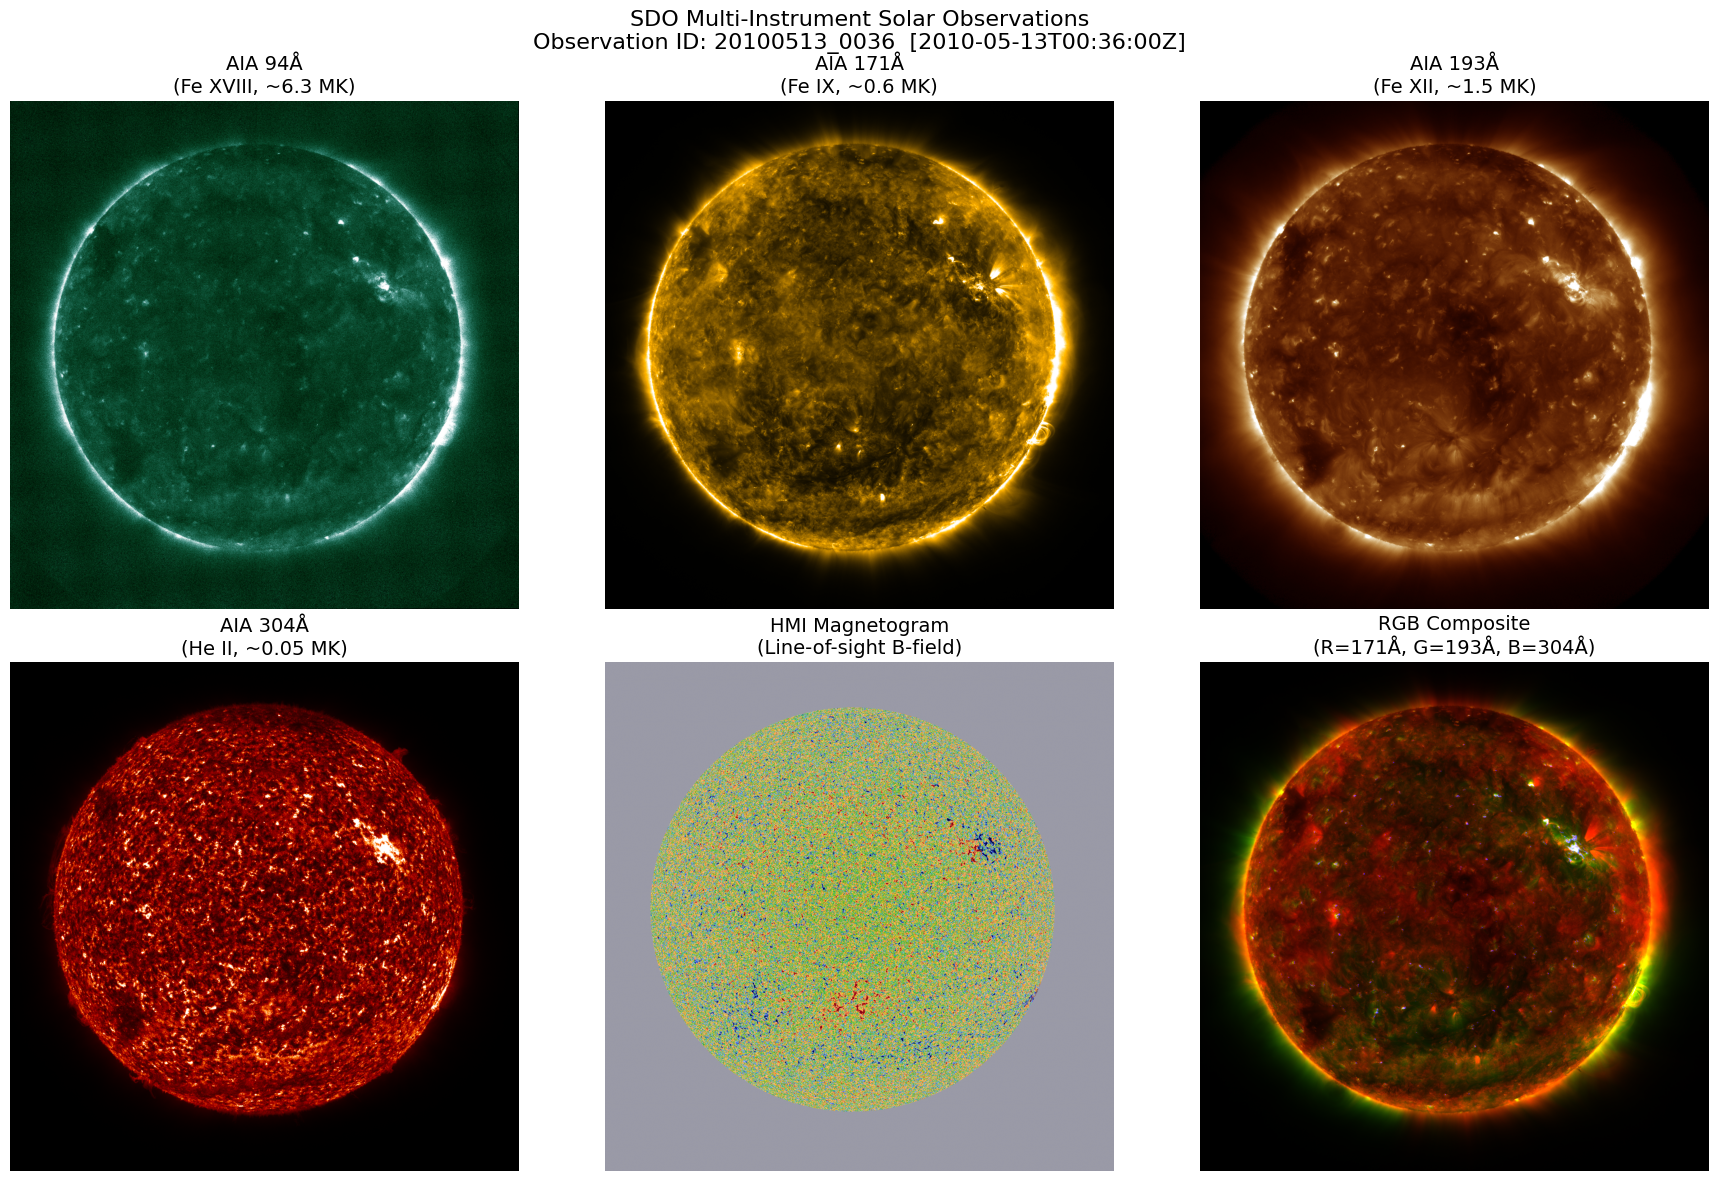

In [7]:
def norm(data, p_low=1.0, p_high=99.5):
    """Percentile clip and normalize array to [0, 1]"""
    vmin = np.percentile(data[np.isfinite(data)], p_low)
    vmax = np.percentile(data[np.isfinite(data)], p_high)
    return np.clip((data - vmin) / (vmax - vmin), 0, 1)


def display_channel(ax, data, title, colormap_name):
    cmap = sunpy_cm.cmlist[colormap_name]
    ax.imshow(cmap(norm(data)[::-1]), origin="lower")
    ax.set_title(title, fontsize=14)
    ax.axis("off")


for b in loaded_batches:
    obs_id = b["observation_id"]
    dt = b["datetime"]
    a94, a171, a193, a304, hmi = (
        b["aia94"],
        b["aia171"],
        b["aia193"],
        b["aia304"],
        b["hmi_m"],
    )

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Top row: AIA 94Å, 171Å, 193Å
    display_channel(axes[0, 0], a94, "AIA 94Å\n(Fe XVIII, ~6.3 MK)", "sdoaia94")
    display_channel(axes[0, 1], a171, "AIA 171Å\n(Fe IX, ~0.6 MK)", "sdoaia171")
    display_channel(axes[0, 2], a193, "AIA 193Å\n(Fe XII, ~1.5 MK)", "sdoaia193")

    # Bottom row: AIA 304Å
    display_channel(axes[1, 0], a304, "AIA 304Å\n(He II, ~0.05 MK)", "sdoaia304")

    # HMI Line-of-sight Magnetogram
    vmax_mag = np.percentile(np.abs(hmi[np.isfinite(hmi)]), 99)
    norm_mag = np.clip((hmi + vmax_mag) / (2 * vmax_mag), 0, 1)
    axes[1, 1].imshow(sunpy_cm.cmlist["hmimag"](norm_mag[::-1]), origin="lower")
    axes[1, 1].set_title("HMI Magnetogram\n(Line-of-sight B-field)", fontsize=14)
    axes[1, 1].axis("off")

    # False-color thermal RGB composite (R=171Å, G=193Å, B=304Å)
    rgb = np.zeros((*a171.shape, 3))
    rgb[:, :, 0] = sunpy_cm.cmlist["sdoaia171"](norm(a171, 1, 99.9))[:, :, 0]
    rgb[:, :, 1] = sunpy_cm.cmlist["sdoaia193"](norm(a193, 1, 99.9))[:, :, 1]
    rgb[:, :, 2] = sunpy_cm.cmlist["sdoaia304"](norm(a304, 1, 99.9))[:, :, 2]

    axes[1, 2].imshow(rgb[::-1], origin="lower")
    axes[1, 2].set_title("RGB Composite\n(R=171Å, G=193Å, B=304Å)", fontsize=14)
    axes[1, 2].axis("off")

    plt.suptitle(
        f"SDO Multi-Instrument Solar Observations\nObservation ID: {obs_id}  [{dt}]",
        fontsize=16,
        y=0.98,
    )
    plt.tight_layout()
    plt.show()